# Áreas de $R_t$ respecto del umbral 1 por períodos epidemiológicos

Este cuaderno prolonga el [análisis diario por inicio de síntomas](06_rt_nacional_inicio_sintomas.ipynb). Usa los mismos registros individuales de Sivigila, pesos seriales de Simpson (media 14,1; DE 2,4 días), ventanas móviles de 14 días y previa $R_t\sim\operatorname{Gamma}(1;0{,}2)$ de [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133). La fuente publicada es [`rt_national_symptom_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_symptom_daily.csv); el [script compartido](../scripts/rt_daily_sivigila.py) vuelve a calcular la posterior a partir de sus conteos para conservar precisión antes de simular. `INI_SIN` es inicio de síntomas **consignado retrospectivamente**, no fecha de infección.

## 1. Significado de las áreas y del balance logarítmico

En cada día $t$ con posterior válida definimos $x_t=R_t-1$ y $T$ como el **número de días con estimación incluidos en el período**, nunca días sin dato. Las métricas anualizadas son

$$A^+=\frac{365{,}25}{T}\sum_t\max(x_t,0),\qquad A^-=\frac{365{,}25}{T}\sum_t\max(-x_t,0),$$
$$A_{\mathrm{neto}}=A^+-A^-=\frac{365{,}25}{T}\sum_t x_t,\qquad L_1=A^++A^-=\frac{365{,}25}{T}\sum_t|x_t|,$$
$$B_{\log}=\frac{365{,}25}{T}\sum_t\ln R_t,\qquad P_+=\frac{100}{T}\sum_t\mathbf 1(R_t>1).$$

$A^+$ es el **impulso supercrítico** y $A^-$ el **área subcrítica**, expresados como días equivalentes por año multiplicados por la distancia promedio a 1; ambos son no negativos. $A_{\mathrm{neto}}$ conserva el signo y $L_1$ mide cuánto oscila la estimación a ambos lados del umbral. $B_{\log}$ conserva otra escala: $\ln R_t\neq R_t-1$ salvo aproximadamente cerca de 1. Ninguna de estas áreas representa casos evitados ni una integral física de transmisión.

[Wallinga y Lipsitch (2007)](https://pubmed.ncbi.nlm.nih.gov/17476782/) vinculan el crecimiento exponencial $r$ con $R$ mediante la **distribución del intervalo de generación**: $1/R=\int_0^\infty g(s)e^{-rs}\,ds$. Cerca de $R=1$, si la distribución y las condiciones cambian lentamente, $r\approx(R-1)/\mu_g$; $\ln R/\mu_g$ es una aproximación adicional que es exacta para un intervalo de generación fijo. Solo bajo esas hipótesis $\int r(t)dt$ se relaciona con $\ln[I(t_2)/I(t_1)]$. Aquí usamos un **intervalo serial externo** como proxy, hay estacionalidad, subregistro, huecos y ventanas solapadas; por ello $B_{\log}$ **no** estima exactamente el cambio logarítmico de incidencia observada.

Los modelos de [Anderson y May (1991)](https://academic.oup.com/book/53038), [McLean y Anderson (1988)](https://www.sciencedirect.com/science/article/pii/0040580988900160) y [Earn et al. (2000)](https://pubmed.ncbi.nlm.nih.gov/10650003/) permiten dinámicas endémicas y cambios del patrón estacional bajo vacunación sin eliminación. [Pawaskar et al. (2022)](https://pubmed.ncbi.nlm.nih.gov/35871869/) documentan una caída de incidencia de varicela en Colombia tras la introducción de la primera dosis, mientras [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) describen heterogeneidad espacial y estacional. La hipótesis de un régimen endémico de menor incidencia es **compatible** con esos antecedentes; estas áreas por sí solas no establecen un nuevo equilibrio ni atribuyen su causa.

## 2. Reproducir y validar las posteriores diarias

Para la ventana que acaba en $t$, la forma es $\alpha_t=1+\sum_{d=t-13}^{t}I_d$ y la tasa $\beta_t=0{,}2+\sum_{d=t-13}^{t}\Lambda_d$. Se verifica **en todos los días publicados** que la media $\alpha_t/\beta_t$ y los cuantiles 2,5 % y 97,5 % de esa Gamma reproducen el estimador. Las semanas ausentes permanecen como `NaN`; el algoritmo espera historia suficiente tras cada hueco.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gamma

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from rt_symptom_sivigila import estimate_onset_rt

source = pd.read_csv(ROOT / "docs/data_processed/numero_reproductivo/rt_national_symptom_daily.csv", parse_dates=["date"])
input_frame = source[["date", "year", "week", "cases", "missing_week"]].copy()
result = estimate_onset_rt(input_frame, mean_si=14.1, sd_si=2.4, window_days=14,
                           prior_mean=5, prior_sd=5)
assert len(result) == 6580 and result.date.equals(source.date)
np.testing.assert_allclose(result.rt, source.rt, rtol=1e-7, atol=1e-8, equal_nan=True)
np.testing.assert_allclose(result.rt_lower_95, source.rt_lower_95, rtol=1e-7, atol=1e-8, equal_nan=True)
np.testing.assert_allclose(result.rt_upper_95, source.rt_upper_95, rtol=1e-7, atol=1e-8, equal_nan=True)

shape = 1 + result.cases.rolling(14, min_periods=14).sum()
rate = 0.2 + result.infectiousness.rolling(14, min_periods=14).sum()
valid = result.rt.notna()
np.testing.assert_allclose((shape / rate)[valid], result.rt[valid], rtol=1e-8)
np.testing.assert_allclose(gamma.ppf(.025, a=shape[valid], scale=1 / rate[valid]),
                           result.rt_lower_95[valid], rtol=1e-8)
np.testing.assert_allclose(gamma.ppf(.975, a=shape[valid], scale=1 / rate[valid]),
                           result.rt_upper_95[valid], rtol=1e-8)
print(f"Posteriores verificadas: {valid.sum():,}; días sin conteo: {result.cases.isna().sum():,}")

Posteriores verificadas: 6,180; días sin conteo: 140


## 3. Períodos, exclusiones y cobertura

Las cinco franjas no se solapan. La comparación principal **excluye del tramo previo** del 1 de enero de 2013 al 31 de marzo de 2014: en el archivo fuente de 2013 solo **37.920 de 93.606** registros elegibles (40,51 %) tienen `INI_SIN` interpretable; véase la [auditoría del cuaderno 06](06_rt_nacional_inicio_sintomas.ipynb). También se excluyen los tres días de enero de 2026 que pertenecen a la semana epidemiológica final de 2025. Una semana sin conteos o un día sin posterior tampoco entra en $T$. La cobertura informa $T$ dividido por los días calendario del tramo **después de retirar el período problemático**; no convierte días faltantes en ceros. Los hitos de julio de 2015 y julio de 2019 son divisiones descriptivas del calendario, no experimentos aleatorizados.

In [2]:
PROBLEM_START = pd.Timestamp("2013-01-01")
PROBLEM_END = pd.Timestamp("2014-03-31")
ANALYSIS_START = pd.Timestamp("2008-01-01")
ANALYSIS_END = pd.Timestamp("2025-12-31")
periods = [
    ("Prevacunación (sin 2013–2014 T1)", "2008-01-01", "2015-06-30"),
    ("Posterior a 1.ª dosis", "2015-07-01", "2019-06-30"),
    ("Posterior al refuerzo, prepandemia", "2019-07-01", "2020-03-14"),
    ("Pandemia de COVID-19", "2020-03-15", "2021-12-31"),
    ("Pospandemia con dos dosis", "2022-01-01", "2025-12-31"),
]

calendar = result.date.between(ANALYSIS_START, ANALYSIS_END)
problem = result.date.between(PROBLEM_START, PROBLEM_END)
period_label = pd.Series(pd.NA, index=result.index, dtype="string")
for label, start, end in periods:
    selected = calendar & result.date.between(start, end) & ~problem
    assert period_label.loc[selected].isna().all()
    period_label.loc[selected] = label
assert period_label.loc[calendar & ~problem].notna().all()
analysis_mask = calendar & ~problem & valid
assert (period_label.loc[analysis_mask].notna()).all()
coverage_rows = []
for label, start, end in periods:
    candidate = calendar & result.date.between(start, end) & ~problem
    observed = candidate & valid
    coverage_rows.append({"período": label, "días calendario elegibles": int(candidate.sum()),
                          "días con posterior": int(observed.sum()),
                          "cobertura %": 100 * observed.sum() / candidate.sum()})
coverage = pd.DataFrame(coverage_rows)
display(coverage.round(2))
print("Días excluidos por calidad en 2013–2014 T1:", int((calendar & problem).sum()))

,período,días calendario elegibles,días con posterior,cobertura %
0,Prevacunación (sin 2013–2014 T1),2283,2205,96.58
1,Posterior a 1.ª dosis,1461,1461,100.00
2,"Posterior al refuerzo, prepandemia",258,258,100.00
3,Pandemia de COVID-19,657,657,100.00
4,Pospandemia con dos dosis,1461,1461,100.00


Días excluidos por calidad en 2013–2014 T1: 455


## 4. Áreas estimadas e incertidumbre condicional

Se usan **4.000 extracciones** por día y período con `np.random.default_rng(2026)` de $\operatorname{Gamma}(\alpha_t,\text{tasa }\beta_t)$. En cada réplica se calculan las seis métricas sobre los mismos $T$ días; la tabla informa **mediana** y cuantiles 2,5 % y 97,5 % de las 4.000 áreas simuladas. También informa el valor obtenido al sustituir cada posterior por su **media**, que no tiene por qué coincidir con la mediana Monte Carlo en las funciones no lineales. El cálculo simula las posteriores **marginales de los días de manera independiente**. El método de Cori comparte conteos entre ventanas de 14 días y no proporciona aquí una posterior conjunta temporal; por eso estos intervalos son resúmenes de esa construcción factorada, probablemente más estrechos si la correlación real es positiva. Tampoco incorporan incertidumbre del intervalo serial, casos faltantes, cambios de notificación o sobredispersión.

In [3]:
DRAW_COUNT = 4000
rng = np.random.default_rng(2026)
metric_labels = {
    "positive": "Impulso supercrítico AUC+",
    "negative": "Área subcrítica AUC−",
    "net": "Balance neto lineal",
    "log": "Balance neto logarítmico",
    "absolute": "Acción total L1",
    "supercritical": "Días supercríticos %",
}


def area_metrics(values):
    """Return six annualized metrics along the final, daily axis."""
    excess = values - 1
    scale = 365.25 / values.shape[-1]
    positive = scale * np.maximum(excess, 0).sum(axis=-1)
    negative = scale * np.maximum(-excess, 0).sum(axis=-1)
    return {
        "positive": positive,
        "negative": negative,
        "net": positive - negative,
        "log": scale * np.log(values).sum(axis=-1),
        "absolute": positive + negative,
        "supercritical": 100 * (values > 1).mean(axis=-1),
    }


summary_rows = []
period_samples = {}
for label, _, _ in periods:
    selected = analysis_mask & period_label.eq(label).fillna(False)
    indices = np.flatnonzero(selected.to_numpy())
    assert len(indices) > 0
    shape_values = shape.to_numpy()[indices]
    rate_values = rate.to_numpy()[indices]
    draws = rng.gamma(shape=shape_values[None, :], scale=1 / rate_values[None, :],
                      size=(DRAW_COUNT, len(indices)))
    assert np.isfinite(draws).all() and (draws > 0).all()
    samples = area_metrics(draws)
    point = area_metrics(result.rt.to_numpy()[indices])
    np.testing.assert_allclose(samples["net"], samples["positive"] - samples["negative"])
    np.testing.assert_allclose(samples["absolute"], samples["positive"] + samples["negative"])
    period_samples[label] = samples
    for key, title in metric_labels.items():
        low, median, high = np.quantile(samples[key], [.025, .5, .975])
        summary_rows.append({"período": label, "métrica": title, "días": len(indices),
                             "valor con media diaria": float(point[key]),
                             "mediana simulada": median, "límite 2,5 %": low,
                             "límite 97,5 %": high})
    del draws
summary = pd.DataFrame(summary_rows)
for title in metric_labels.values():
    display(summary.loc[summary.métrica.eq(title)].drop(columns="métrica").round(3))

,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
0,Prevacunación (sin 2013–2014 T1),2205,16.118,16.345,16.150,16.551
6,Posterior a 1.ª dosis,1461,16.706,16.851,16.600,17.112
12,"Posterior al refuerzo, prepandemia",258,13.049,13.453,12.770,14.143
18,Pandemia de COVID-19,657,20.326,21.710,20.634,22.777
24,Pospandemia con dos dosis,1461,20.519,21.008,20.542,21.476


,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
1,Prevacunación (sin 2013–2014 T1),2205,14.651,14.880,14.718,15.045
7,Posterior a 1.ª dosis,1461,15.786,15.932,15.742,16.129
13,"Posterior al refuerzo, prepandemia",258,13.565,13.975,13.365,14.571
19,Pandemia de COVID-19,657,23.127,24.511,23.655,25.357
25,Pospandemia con dos dosis,1461,16.980,17.458,17.096,17.833


,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
2,Prevacunación (sin 2013–2014 T1),2205,1.467,1.466,1.197,1.734
8,Posterior a 1.ª dosis,1461,0.920,0.920,0.590,1.250
14,"Posterior al refuerzo, prepandemia",258,-0.517,-0.521,-1.428,0.441
20,Pandemia de COVID-19,657,-2.801,-2.788,-4.223,-1.342
26,Pospandemia con dos dosis,1461,3.539,3.549,2.944,4.159


,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
3,Prevacunación (sin 2013–2014 T1),2205,-2.827,-2.893,-3.174,-2.599
9,Posterior a 1.ª dosis,1461,-1.403,-1.459,-1.788,-1.131
15,"Posterior al refuerzo, prepandemia",258,-2.119,-2.206,-3.119,-1.238
21,Pandemia de COVID-19,657,-9.415,-9.887,-11.341,-8.432
27,Pospandemia con dos dosis,1461,0.632,0.456,-0.150,1.056


,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
4,Prevacunación (sin 2013–2014 T1),2205,30.768,31.228,30.980,31.480
10,Posterior a 1.ª dosis,1461,32.492,32.787,32.476,33.100
16,"Posterior al refuerzo, prepandemia",258,26.614,27.434,26.570,28.307
22,Pandemia de COVID-19,657,43.454,46.217,44.977,47.516
28,Pospandemia con dos dosis,1461,37.498,38.466,37.902,39.038


,período,días,valor con media diaria,mediana simulada,"límite 2,5 %","límite 97,5 %"
5,Prevacunación (sin 2013–2014 T1),2205,53.016,53.152,52.336,53.968
11,Posterior a 1.ª dosis,1461,56.194,56.057,55.168,56.879
17,"Posterior al refuerzo, prepandemia",258,50.388,50.388,47.287,53.488
23,Pandemia de COVID-19,657,52.207,50.533,48.402,52.664
29,Pospandemia con dos dosis,1461,53.183,52.909,51.745,54.004


## 5. Diagnóstico anual y figura

La tabla anual aplica las mismas fórmulas a la **media posterior diaria** de cada año y excluye el tramo problemático. Al dividir por $T$ observado y multiplicar por 365,25, una anualización de un año incompleto puede resultar inestable y **no** debe confundirse con el área realmente acumulada durante todo ese año. En 2013 no quedan días analizables tras la exclusión; 2014 comienza en abril. El gráfico deja 2013 sin barra y marca 2014 como parcial. Se trazan $+AUC^+$ hacia arriba, $-AUC^-$ hacia abajo y el balance $A_{\rm neto}$; las barras no son intervalos de credibilidad.

,año,días elegibles,días con posterior,cobertura %,impulso AUC+,área AUC−,balance neto,balance logarítmico,días supercríticos %
0,2008,366,324,88.52,18.46,18.88,-0.42,-18.59,65.43
1,2009,365,329,90.14,9.82,14.07,-4.25,-5.62,34.35
2,2010,365,365,100.00,18.27,10.54,7.73,6.12,62.74
3,2011,365,365,100.00,20.78,15.96,4.82,2.00,53.97
4,2012,366,366,100.00,14.38,15.15,-0.77,-2.61,47.81
5,2013,0,0,NaN,NaN,NaN,NaN,NaN,NaN
6,2014,275,275,100.00,12.85,16.79,-3.95,-5.90,54.55
7,2015,365,365,100.00,15.60,13.96,1.65,-0.35,51.23
8,2016,366,366,100.00,16.52,14.91,1.61,-0.49,54.64
9,2017,365,365,100.00,14.45,17.39,-2.94,-5.21,52.33


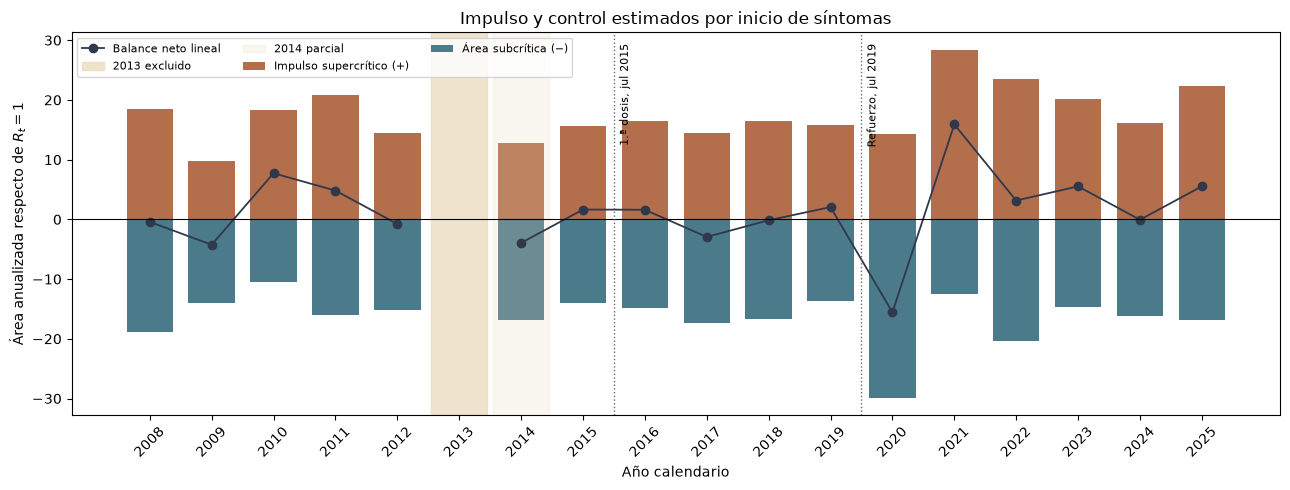

In [4]:
annual_rows = []
for year in range(2008, 2026):
    eligible_year = calendar & result.date.dt.year.eq(year) & ~problem
    selected = eligible_year & valid
    values = result.loc[selected, "rt"].to_numpy()
    metrics = area_metrics(values) if len(values) else None
    annual_rows.append({
        "año": year,
        "días elegibles": int(eligible_year.sum()),
        "días con posterior": len(values),
        "cobertura %": 100 * len(values) / eligible_year.sum() if eligible_year.sum() else np.nan,
        "impulso AUC+": float(metrics["positive"]) if metrics else np.nan,
        "área AUC−": float(metrics["negative"]) if metrics else np.nan,
        "balance neto": float(metrics["net"]) if metrics else np.nan,
        "balance logarítmico": float(metrics["log"]) if metrics else np.nan,
        "días supercríticos %": float(metrics["supercritical"]) if metrics else np.nan,
    })
annual = pd.DataFrame(annual_rows)
np.testing.assert_allclose(annual["impulso AUC+"] - annual["área AUC−"],
                           annual["balance neto"], equal_nan=True)
display(annual.round(2))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(annual["año"], annual["impulso AUC+"], color="#b36e4c", width=.75,
       label="Impulso supercrítico (+)")
ax.bar(annual["año"], -annual["área AUC−"], color="#4b7b8a", width=.75,
       label="Área subcrítica (−)")
ax.plot(annual["año"], annual["balance neto"], marker="o", color="#30384b",
        lw=1.3, label="Balance neto lineal")
ax.axhline(0, color="black", lw=.8)
ax.axvspan(2012.55, 2013.45, color="#e9d5b5", alpha=.65, label="2013 excluido")
ax.axvspan(2013.55, 2014.45, color="#e9d5b5", alpha=.2, label="2014 parcial")
for year, label in ((2015.5, "1.ª dosis, jul 2015"), (2019.5, "Refuerzo, jul 2019")):
    ax.axvline(year, color="#6c6a65", ls=":", lw=1)
    ax.text(year+.08, .97, label, rotation=90, va="top", ha="left",
            transform=ax.get_xaxis_transform(), fontsize=8)
ax.set(xlabel="Año calendario", ylabel="Área anualizada respecto de $R_t=1$",
       title="Impulso y control estimados por inicio de síntomas")
ax.set_xticks(range(2008, 2026))
ax.tick_params(axis="x", rotation=45)
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Conteos que acompañan al estimador

Para distinguir la **escala de casos registrados** de las áreas de $R_t$, resumimos los conteos diarios sobre exactamente los mismos días de cada período. Estos son conteos nacionales con inicio interpretable, **no tasas de incidencia por población**; no se ajustan por cambios demográficos, subregistro ni calidad desigual de las fechas. La exclusión de 2013–2014 T1 afecta especialmente la media previa.

In [5]:
count_rows = []
for label, _, _ in periods:
    selected = analysis_mask & period_label.eq(label).fillna(False)
    period_data = result.loc[selected]
    count_rows.append({
        "período": label,
        "días con posterior": len(period_data),
        "casos diarios, media": period_data.cases.mean(),
        "casos diarios, mediana": period_data.cases.median(),
        "media diaria de Rt": period_data.rt.mean(),
        "días con Rt > 1, %": 100 * period_data.rt.gt(1).mean(),
    })
counts_by_period = pd.DataFrame(count_rows)
display(counts_by_period.round(3))

,período,días con posterior,"casos diarios, media","casos diarios, mediana",media diaria de Rt,"días con Rt > 1, %"
0,Prevacunación (sin 2013–2014 T1),2205,251.455,242.0,1.004,53.016
1,Posterior a 1.ª dosis,1461,253.845,241.0,1.003,56.194
2,"Posterior al refuerzo, prepandemia",258,163.686,166.0,0.999,50.388
3,Pandemia de COVID-19,657,32.671,26.0,0.992,52.207
4,Pospandemia con dos dosis,1461,74.289,72.0,1.010,53.183


## 6. Conclusiones basadas en la ejecución

La celda siguiente sintetiza los valores calculados; luego se interpretan sin atribución causal automática.

In [6]:
def get_metric(period_name, key):
    """Retrieve one simulated metric's median and interval for a period."""
    row = summary.loc[summary.período.eq(period_name) & summary.métrica.eq(metric_labels[key])].iloc[0]
    return row["mediana simulada"], row["límite 2,5 %"], row["límite 97,5 %"]

for label, _, _ in periods:
    observed_days = int(coverage.loc[coverage.período.eq(label), "días con posterior"].iloc[0])
    positive = get_metric(label, "positive")
    negative = get_metric(label, "negative")
    net = get_metric(label, "net")
    logarithmic = get_metric(label, "log")
    print(f"{label}: T={observed_days}; AUC+={positive[0]:.2f} [{positive[1]:.2f}, {positive[2]:.2f}]; "
          f"AUC−={negative[0]:.2f} [{negative[1]:.2f}, {negative[2]:.2f}]; "
          f"neto={net[0]:.2f} [{net[1]:.2f}, {net[2]:.2f}]; "
          f"log={logarithmic[0]:.2f} [{logarithmic[1]:.2f}, {logarithmic[2]:.2f}]")

Prevacunación (sin 2013–2014 T1): T=2205; AUC+=16.35 [16.15, 16.55]; AUC−=14.88 [14.72, 15.04]; neto=1.47 [1.20, 1.73]; log=-2.89 [-3.17, -2.60]
Posterior a 1.ª dosis: T=1461; AUC+=16.85 [16.60, 17.11]; AUC−=15.93 [15.74, 16.13]; neto=0.92 [0.59, 1.25]; log=-1.46 [-1.79, -1.13]
Posterior al refuerzo, prepandemia: T=258; AUC+=13.45 [12.77, 14.14]; AUC−=13.97 [13.36, 14.57]; neto=-0.52 [-1.43, 0.44]; log=-2.21 [-3.12, -1.24]
Pandemia de COVID-19: T=657; AUC+=21.71 [20.63, 22.78]; AUC−=24.51 [23.65, 25.36]; neto=-2.79 [-4.22, -1.34]; log=-9.89 [-11.34, -8.43]
Pospandemia con dos dosis: T=1461; AUC+=21.01 [20.54, 21.48]; AUC−=17.46 [17.10, 17.83]; neto=3.55 [2.94, 4.16]; log=0.46 [-0.15, 1.06]


### Lectura epidemiológica

**Relación teórica y límite de esta aplicación.** [Wallinga y Lipsitch (2007)](https://pubmed.ncbi.nlm.nih.gov/17476782/) relacionan $R$ y la tasa de crecimiento mediante el intervalo de generación. Cerca del umbral y bajo crecimiento local aproximadamente estable, $r\approx(R-1)/\mu_g$ y, con hipótesis adicionales, $r\approx\ln R/\mu_g$; entonces la integral de $r$ se vincula al cambio logarítmico de incidencia. Nuestras sumas anualizadas de $R_t-1$ y $\ln R_t$ **no reconstruyen esa integral exactamente**, porque $R_t$ se estima con ventanas solapadas, un intervalo serial usado como proxy del de generación y registros retrospectivos incompletos. El Monte Carlo parte de las posteriores conjugadas del marco de [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133) y [Thompson et al. (2019)](https://doi.org/10.1016/j.epidem.2019.100356), pero muestrear independientemente las marginales diarias es una **decisión adicional de este cuaderno**, no una posterior conjunta propuesta por esos autores.

**El impulso no cae de modo sostenido después de los hitos.** Tras excluir 2013–2014 T1, el período previo aporta **2.205 días** con posterior: $AUC^+$ mediano **16,35** (intervalo simulado 95 % **16,15–16,55**), $AUC^-$ **14,88** (**14,72–15,04**) y balance lineal **+1,47** (**+1,20 a +1,73**). En los **1.461 días** posteriores a la primera dosis hasta junio de 2019, $AUC^+$ es **16,85** (**16,60–17,11**) y $AUC^-$ **15,93** (**15,74–16,13**); el balance es **+0,92** (**+0,59 a +1,25**). Las diferencias son resúmenes del estimador, no efectos vacunales. En los **258 días** entre el refuerzo y el inicio del tramo pandémico el balance es **−0,52** (**−1,43 a +0,44**): el intervalo simulado cruza cero.

**La pandemia concentra oscilaciones de signo opuesto.** En sus **657 días**, $AUC^+$ es **21,71** (**20,63–22,78**) y $AUC^-$ **24,51** (**23,65–25,36**), con balance lineal **−2,79** (**−4,22 a −1,34**). La tabla anual muestra que **2020** aporta un balance puntual de **−15,55**, mientras **2021** aporta **+15,90**. Una cifra para toda la pandemia oculta esa inversión. En **2022–2025**, sobre **1.461 días**, $AUC^+$ es **21,01** (**20,54–21,48**), $AUC^-$ **17,46** (**17,10–17,83**) y balance **+3,55** (**+2,94 a +4,16**). Estos valores no permiten afirmar que la transmisión entró en un nuevo equilibrio de menor incidencia.

**El signo del balance depende de la escala.** Antes de julio de 2015, el balance lineal mediano es **+1,47**, mientras el logarítmico es **−2,89** (**−3,17 a −2,60**): pocos días con $R_t$ alto pueden elevar la media aritmética aunque los valores inferiores a uno reduzcan la suma de logaritmos. En 2022–2025 el balance logarítmico es **+0,46** (**−0,15 a +1,06**), cuyo intervalo simulado también cruza cero. Ni el balance lineal ni el logarítmico equivalen al cambio observado de incidencia entre extremos.

**Los conteos no respaldan una caída sostenida inmediata tras 2015.** La media de registros diarios con fecha interpretable en los días analizados es **251,5** antes de julio de 2015 y **253,8** entre julio de 2015 y junio de 2019; desciende a **163,7** en el breve tramo posterior al refuerzo y anterior a la pandemia, a **32,7** durante la pandemia, y es **74,3** en 2022–2025. Son conteos, no tasas ajustadas de incidencia, y la preselección excluye 2013–2014 T1. [Pawaskar et al. (2022)](https://pubmed.ncbi.nlm.nih.gov/35871869/) encuentran una reducción de la **incidencia** en su propio análisis nacional hasta 2019; ese hallazgo no autoriza a describir **estos** conteos seleccionados como un descenso continuo desde 2015. [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) documentan además variación climática y estacional de la varicela colombiana.

**El equilibrio endémico es una hipótesis teórica, no una conclusión identificada aquí.** Los modelos de [Anderson y May (1991)](https://academic.oup.com/book/53038), [McLean y Anderson (1988)](https://www.sciencedirect.com/science/article/pii/0040580988900160) y [Earn et al. (2000)](https://pubmed.ncbi.nlm.nih.gov/10650003/) muestran que la vacunación parcial puede cambiar el nivel y la dinámica recurrente de una infección sin eliminarla. El patrón observado de áreas a ambos lados de 1 es compatible con oscilaciones endémicas, pero nuestros balances no muestran una fase sostenida y limpia de $\sum\ln R_t<0$ seguida de un equilibrio demostrado: el balance logarítmico es **−2,89** antes de julio de 2015, **−1,46** después de la primera dosis, **−2,21** en el tramo breve prepandémico, **−9,89** durante la pandemia y **+0,46** en 2022–2025. Las duraciones y condiciones de vigilancia difieren. No se puede asignar a la vacuna un cambio de equilibrio con este diseño.

**La incertidumbre es parcial.** Vacunación, estructura de edades, clima, cierres y reaperturas por COVID-19, cambios de vigilancia y la calidad de `INI_SIN` varían a la vez. No se ha ajustado un contrafactual. Las 4.000 muestras por día usan posteriores Gamma correctas individualmente, pero su combinación independiente ignora la dependencia entre ventanas solapadas. Los intervalos de áreas no son pruebas independientes sobre 4.000 epidemias, no cubren el 59,5 % de fechas `INI_SIN` faltantes en 2013 ni otros errores de vigilancia. Para inferencia causal o de cambio de régimen harían falta un modelo dinámico conjunto, retrasos y faltantes explícitos, covariables climáticas y demográficas, y una comparación contrafactual.